Autor: Dobrosav Tufegdžić
Prvi zadataak

In [ ]:
#import biblioteka
import cv2
import matplotlib.pyplot as plt
import numpy as np
import glob
import os
import csv
import torch
import torchvision.transforms as transforms
from torchvision.models import resnet18
from PIL import Image
from sklearn.metrics.pairwise import cosine_similarity


In [ ]:
#funkcije za obradu slika i rad s konturama
def load_image(image_path):
    image = cv2.imread(image_path)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def image_gray(image, side='front'):
    blue = image[:, :, 2]
    blue = cv2.GaussianBlur(blue, (5, 5), 0)
    blue_boosted = cv2.equalizeHist(blue)
    blue_boosted = np.uint8(np.absolute(blue_boosted))
    return blue

def image_bin(image_gs):
    return cv2.threshold(image_gs, 20, 120, cv2.THRESH_BINARY)[1]

def image_bin_adaptive(image_gs):
    return cv2.adaptiveThreshold(image_gs, 120, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 401, 10)

def invert(image):
    return 255 - image

def rotate_image(image, angle):
    center = (image.shape[1] // 2, image.shape[0] // 2)
    rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    return cv2.warpAffine(image, rotation_matrix, (image.shape[1], image.shape[0]))

def find_largest_contour(image_bin):
    contours, _ = cv2.findContours(image_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return max(contours, key=cv2.contourArea) if contours else None

def dilate(image_bin):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    return cv2.dilate(image_bin, kernel, iterations=1)

def erode(image_bin):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    return cv2.erode(image_bin, kernel, iterations=1)

def load_dataset_images(folder_path):
    return glob.glob(os.path.join(folder_path, '*.png'))

def isolate_tile(image, contour):
    mask = np.zeros_like(image[:, :, 0])
    cv2.drawContours(mask, [contour], -1, 255, thickness=cv2.FILLED)
    isolated_tile = cv2.bitwise_and(image, image, mask=mask)
    x, y, w, h = cv2.boundingRect(contour)
    isolated_tile = isolated_tile[y:y+h, x:x+w]
    target_width, target_height = 1280, 960
    scale = min(target_width / w, target_height / h)
    new_size = (int(w * scale), int(h * scale))
    resized_tile = cv2.resize(isolated_tile, new_size, interpolation=cv2.INTER_AREA)
    canvas = np.zeros((target_height, target_width, 3), dtype=np.uint8)
    x_offset = (target_width - resized_tile.shape[1]) // 2
    y_offset = (target_height - resized_tile.shape[0]) // 2
    canvas[y_offset:y_offset + resized_tile.shape[0], x_offset:x_offset + resized_tile.shape[1]] = resized_tile
    return canvas

def save_image(image, path):
    image_bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    cv2.imwrite(path, image_bgr)


In [ ]:
#logika za obradu slika i izolaciju crepa
reference_image_path_front = './base_tiles/tile_front_larger.png'
reference_image_path_back = './base_tiles/tile_back_larger.png'
reference_image_front = rotate_image(load_image(reference_image_path_front), 90)
reference_image_back = rotate_image(load_image(reference_image_path_back), 90)
reference_image_front = cv2.resize(reference_image_front, (0, 0), fx=0.5, fy=0.5)
reference_image_back = cv2.resize(reference_image_back, (0, 0), fx=0.5, fy=0.5)

folder_path_front = './dataset/front/'
folder_path_back = './dataset/back/'
image_files_front = load_dataset_images(folder_path_front)
image_files_back = load_dataset_images(folder_path_back)

for image_path in image_files_front:
    im = load_image(image_path)
    im_gray = invert(image_gray(im))
    im_bin = dilate(erode(image_bin_adaptive(im_gray)))
    largest_contour = find_largest_contour(im_bin)
    if largest_contour is not None:
        tile = isolate_tile(im, largest_contour)
        save_image(tile, './isolated_tiles/front/' + os.path.basename(image_path))

for image_path in image_files_back:
    im = load_image(image_path)
    im_gray = invert(image_gray(im))
    im_bin = image_bin_adaptive(im_gray)
    largest_contour = find_largest_contour(im_bin)
    if largest_contour is not None:
        tile = isolate_tile(im, largest_contour)
        save_image(tile, './isolated_tiles/back/' + os.path.basename(image_path))


In [ ]:
#logika za klasifikaciju slika koristeći ResNet18
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = resnet18(pretrained=True)
model = torch.nn.Sequential(*list(model.children())[:-1])
model = model.to(device)
model.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

def extract_features(image_path):
    image = Image.open(image_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        features = model(input_tensor)
    return features.squeeze().cpu().numpy().flatten()

ref_front_feat = extract_features('./base_tiles/tile_front_larger.png')
ref_back_feat = extract_features('./base_tiles/tile_back_larger.png')
ref_combined = np.concatenate([ref_front_feat, ref_back_feat])

front_paths = sorted(glob.glob('./dataset/front/*.png'))
back_paths = sorted(glob.glob('./dataset/back/*.png'))

assert len(front_paths) == len(back_paths), "Broj prednjih i zadnjih slika nije isti!"

similarity_threshold = 0.74

for front_path, back_path in zip(front_paths, back_paths):
    name = os.path.basename(front_path).replace('_napred_', '_')
    front_name = os.path.basename(front_path)
    back_name = os.path.basename(back_path)
    true_label = 'Zadovoljavajuć' if name.startswith('PK') else 'Nezadovoljavajuć'

    front_feat = extract_features(front_path)
    back_feat = extract_features(back_path)
    combined_feat = np.concatenate([front_feat, back_feat])

    similarity = cosine_similarity(
        combined_feat.reshape(1, -1),
        ref_combined.reshape(1, -1)
    )[0][0]

    pred_label = 'Zadovoljavajuć' if similarity >= similarity_threshold else 'Nezadovoljavajuć'

    print(f"{name} => Pred: {pred_label} | True: {true_label} | Similarity: {similarity:.4f}")
    results.append([front_name,back_name, pred_label, true_label, similarity])

# čuvanje rezultata u CSV fajl
with open("classification_results_resnet.csv", "w", newline='') as f:
    writer = csv.writer(f)
    writer.writerow(["Front image","Back image", "Predicted", "True", "Similarity"])
    writer.writerows(results)



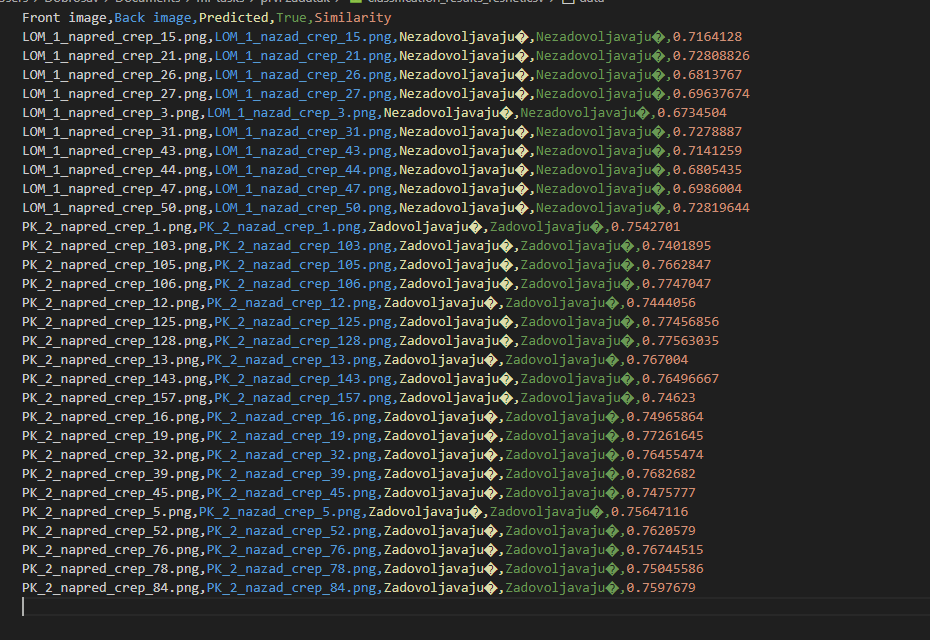

Odrađeni koraci:
1. Učitavanje i izolacija crepa iz test seta
2. Korišćenje resnet18 modela za klasifikaciju(jer je pre-trained)
3. Ekstrakcija ključnih tačaka iz idealnog crepa
4. Poređenje sa crepovima u datasetu
5. Obrada i čuvanje rezultata